<a href="https://colab.research.google.com/github/Bassma-Chemaou/projet6-3d/blob/main/notebooks/03b_vae_generation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import drive
drive.mount("/content/drive")

import os, sys, time, random, joblib
if not os.path.exists("/content/projet6-3d"):
    !git clone https://github.com/Bassma-Chemaou/projet6-3d.git /content/projet6-3d
%cd /content/projet6-3d
!git pull -q
sys.path.insert(0, "/content/projet6-3d")

import numpy as np, torch, torch.nn as nn
import matplotlib.pyplot as plt, pandas as pd
from pathlib import Path
from sklearn.mixture import GaussianMixture
from google.colab import files
from src.losses import chamfer_batch
from src.metrics import pairwise_cd, gen_metrics
from src.data.datasets import load_processed

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
dev = torch.device("cpu")

D = Path("/content/drive/MyDrive/projet6-3d/processed")
CK = Path("/content/drive/MyDrive/projet6-3d/checkpoints")
X, Y, cats = load_processed(D)
print({s: tuple(X[s].shape) for s in X}, cats, "| CPU")
print("Checkpoints sur Drive :", sorted(p.name for p in CK.glob("*.pth")))


class PointNetVAE(nn.Module):
    def __init__(self, n_points=2048, latent=128, n_classes=0):
        super().__init__()
        ch, layers = [3, 64, 128, 256, 512], []
        for i in range(4):
            layers += [nn.Conv1d(ch[i], ch[i + 1], 1), nn.BatchNorm1d(ch[i + 1]), nn.ReLU()]
        self.enc = nn.Sequential(*layers)
        self.fc_mu, self.fc_logvar = nn.Linear(512, latent), nn.Linear(512, latent)
        self.dec = nn.Sequential(nn.Linear(latent + n_classes, 512), nn.ReLU(),
                                 nn.Linear(512, 1024), nn.ReLU(),
                                 nn.Linear(1024, n_points * 3))
        self.n, self.n_classes, self.latent = n_points, n_classes, latent

    def encode(self, x):
        h = self.enc(x.transpose(1, 2)).max(2)[0]
        return self.fc_mu(h), self.fc_logvar(h)

    def decode(self, z, y=None):
        if self.n_classes:
            z = torch.cat([z, nn.functional.one_hot(y, self.n_classes).float()], 1)
        return self.dec(z).view(-1, self.n, 3)


def load_vae(name):
    m = PointNetVAE(2048, 128).to(dev)
    m.load_state_dict(torch.load(CK / f"{name}_best.pth", map_location=dev)); m.eval(); return m

@torch.no_grad()
def posterior_stats(model, Xs, bs=64):
    mus = []
    for i in range(0, len(Xs), bs):
        mus.append(model.encode(Xs[i:i + bs].to(dev))[0].cpu())
    return torch.cat(mus)

@torch.no_grad()
def decode_z(model, z):
    return torch.cat([model.decode(z[i:i + 100].to(dev)).cpu() for i in range(0, len(z), 100)])

@torch.no_grad()
def interpolate(model, z1, z2, steps=7):
    z = torch.stack([(1 - t) * z1 + t * z2 for t in torch.linspace(0, 1, steps)]).to(dev)
    return model.decode(z).cpu()

def show_clouds(clouds, titles=None, ncols=4, size=1):
    nrows = (len(clouds) + ncols - 1) // ncols
    fig = plt.figure(figsize=(2.4 * ncols, 2.4 * nrows))
    for i, p in enumerate(clouds):
        p = p.cpu().numpy() if torch.is_tensor(p) else p
        ax = fig.add_subplot(nrows, ncols, i + 1, projection="3d")
        ax.scatter(p[:, 0], p[:, 1], p[:, 2], s=size)
        ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1)
        ax.set_box_aspect((1, 1, 1)); ax.set_axis_off()
        if titles: ax.set_title(titles[i], fontsize=8)
    plt.tight_layout(); return fig

N_GEN = len(X["test"])
sel = torch.randperm(2048, generator=torch.Generator().manual_seed(SEED))[:1024]
R, T = X["test"][:, :1024], X["train"][:, :1024]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/projet6-3d
{'train': (1353, 2048, 3), 'val': (239, 2048, 3), 'test': (400, 2048, 3)} ['chair', 'table', 'sofa', 'bed'] | CPU
Checkpoints sur Drive : ['ae_baseline_best.pth', 'cvae_points_best.pth', 'vae_points_best.pth', 'vae_points_beta0.01_best.pth', 'vae_points_beta0.03_best.pth']


Échantillons par composante : [34 66 33 59 88 23 74 23] | 1 000 formes en 0.30 s


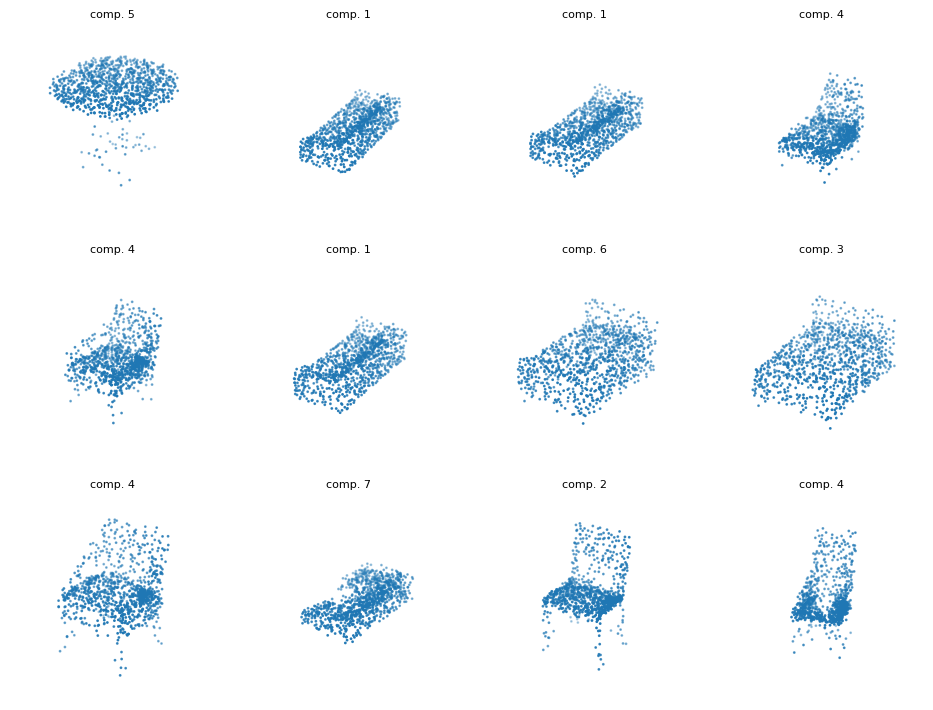

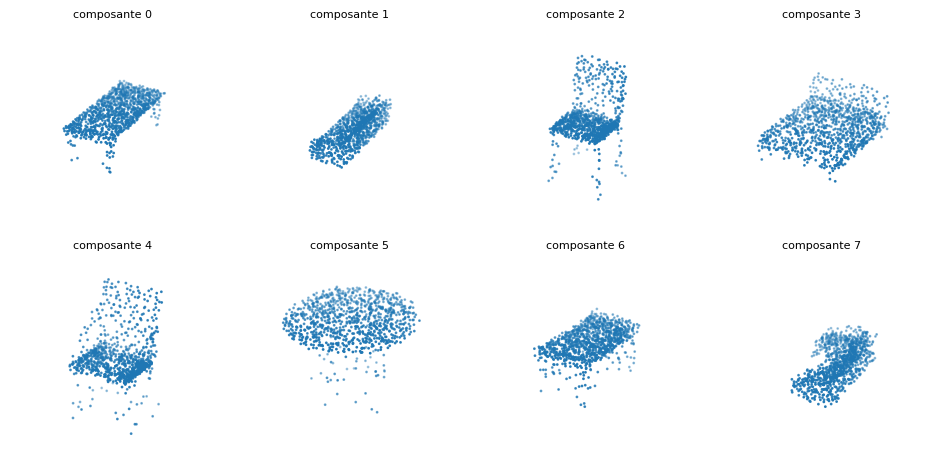

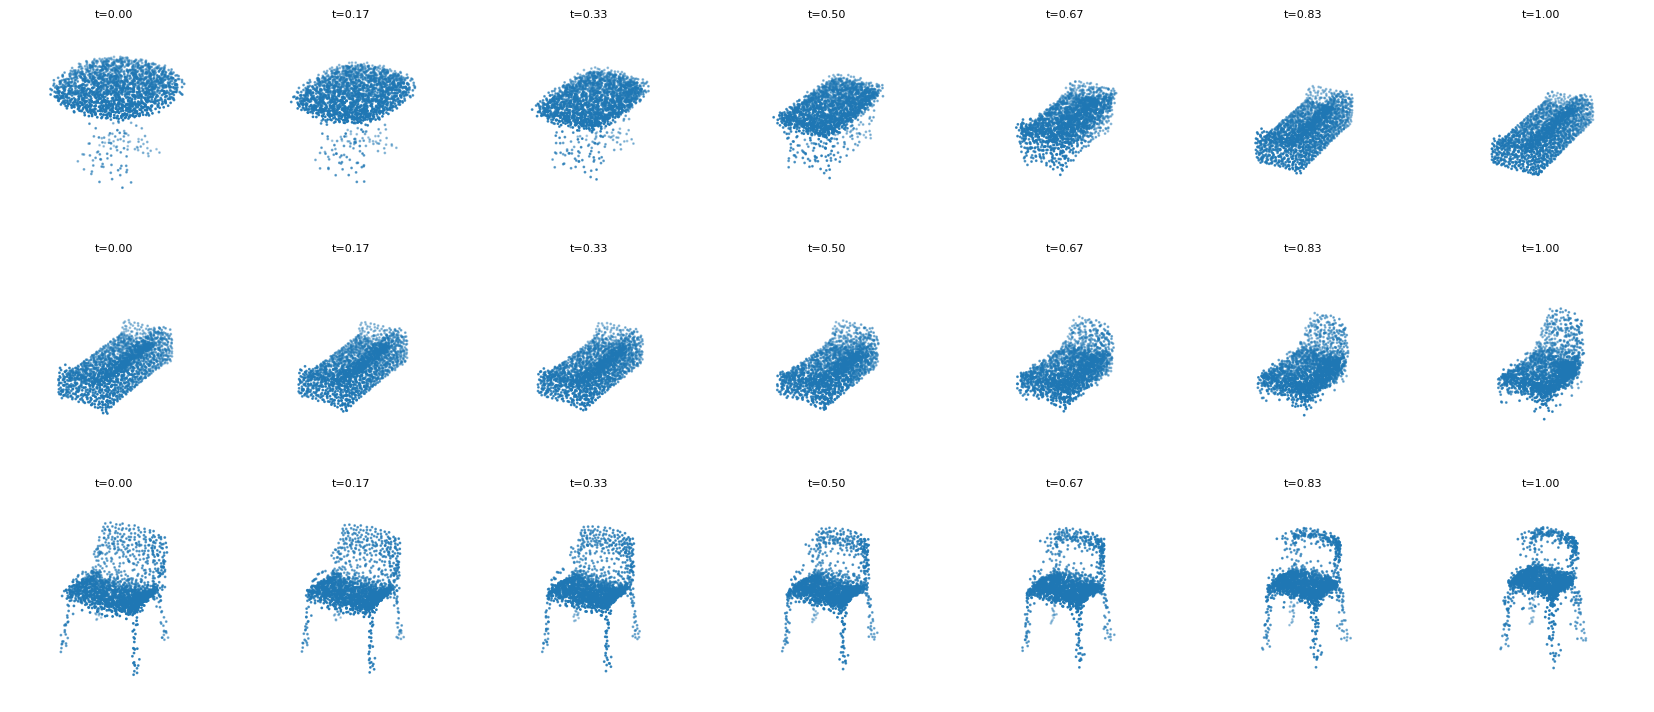

In [4]:
vae = load_vae("vae_points")
mu_tr = posterior_stats(vae, X["train"])
gm = GaussianMixture(n_components=8, covariance_type="diag", reg_covar=1e-4,
                     random_state=SEED).fit(mu_tr.numpy())     # même ajustement qu'avant
joblib.dump(gm, CK / "gmm_prior_k8.joblib")                    # sera réutilisé par la démo

t0 = time.time()
z, comp = gm.sample(1000)                                      # durée pour 1 000 formes
_ = decode_z(vae, torch.from_numpy(z).float())
t_gen = time.time() - t0
z, comp = gm.sample(N_GEN)                                     # mêmes 400 échantillons qu'à la cellule 11
Gz = decode_z(vae, torch.from_numpy(z).float())
print("Échantillons par composante :", np.bincount(comp), "| 1 000 formes en %.2f s" % t_gen)

# (1) 12 formes tirées AU HASARD (les 12 premières venaient toutes de la composante 0)
perm = np.random.default_rng(SEED).permutation(N_GEN)[:12]
fig_gen = show_clouds([Gz[i, sel] for i in perm], [f"comp. {comp[i]}" for i in perm], ncols=4); plt.show()

# (2) une forme par composante
first = [int(np.where(comp == k)[0][0]) for k in range(8)]
fig_comp = show_clouds([Gz[i, sel] for i in first], [f"composante {k}" for k in range(8)], ncols=4); plt.show()

# (3) interpolations : deux entre formes générées, une entre deux chaises du test
zz = torch.from_numpy(z[perm[:4]]).float()
row_a, row_b = interpolate(vae, zz[0], zz[1]), interpolate(vae, zz[2], zz[3])
c = np.where(Y["test"] == 0)[0][:2]
with torch.no_grad(): mu_c, _ = vae.encode(X["test"][c].to(dev))
row_c = interpolate(vae, mu_c[0].cpu(), mu_c[1].cpu())
fig_interp = show_clouds(list(row_a) + list(row_b) + list(row_c),
                         [f"t={t:.2f}" for t in np.linspace(0, 1, 7)] * 3, ncols=7); plt.show()

In [5]:
rows = [
 ("1e-3", "N(0,I) (guide)",      0.00632, 0.0505, 0.0475, 0.9950),
 ("1e-3", "gaussienne ajustée",  0.00632, 0.0177, 0.3550, 0.8438),
 ("1e-3", "GMM diag k=8",        0.00632, 0.0168, 0.3400, 0.7663),
 ("1e-2", "N(0,I) (guide)",      0.0080,  0.0225, 0.2675, 0.8637),
 ("1e-2", "gaussienne ajustée",  0.0080,  0.0172, 0.3775, 0.8238),
 ("1e-2", "GMM diag k=8",        0.0080,  0.0176, 0.3525, 0.8225),
 ("3e-2", "N(0,I) (guide)",      0.0100,  0.0181, 0.3325, 0.8438),
 ("3e-2", "gaussienne ajustée",  0.0100,  0.0177, 0.3375, 0.8562),
 ("3e-2", "GMM diag k=8",        0.0100,  0.0189, 0.3400, 0.8687),
]
tab = pd.DataFrame(rows, columns=["β", "prior", "CD test", "MMD-CD", "COV", "1-NNA"])
tab["Latent"], tab["Points"] = 128, 2048
print(tab.to_string(index=False))

os.makedirs("/content/results", exist_ok=True)
fig_gen.savefig("/content/results/vae_generation.png", dpi=130, bbox_inches="tight")
fig_comp.savefig("/content/results/vae_composantes.png", dpi=130, bbox_inches="tight")
fig_interp.savefig("/content/results/vae_interpolation.png", dpi=130, bbox_inches="tight")
tab.to_csv("/content/results/tableau_A_vae.csv", index=False)
tab.to_csv("/content/drive/MyDrive/projet6-3d/resultats_vae.csv", index=False)
for f in ["vae_generation.png", "vae_composantes.png", "vae_interpolation.png", "tableau_A_vae.csv"]:
    files.download(f"/content/results/{f}")

   β              prior  CD test  MMD-CD    COV  1-NNA  Latent  Points
1e-3     N(0,I) (guide)  0.00632  0.0505 0.0475 0.9950     128    2048
1e-3 gaussienne ajustée  0.00632  0.0177 0.3550 0.8438     128    2048
1e-3       GMM diag k=8  0.00632  0.0168 0.3400 0.7663     128    2048
1e-2     N(0,I) (guide)  0.00800  0.0225 0.2675 0.8637     128    2048
1e-2 gaussienne ajustée  0.00800  0.0172 0.3775 0.8238     128    2048
1e-2       GMM diag k=8  0.00800  0.0176 0.3525 0.8225     128    2048
3e-2     N(0,I) (guide)  0.01000  0.0181 0.3325 0.8438     128    2048
3e-2 gaussienne ajustée  0.01000  0.0177 0.3375 0.8562     128    2048
3e-2       GMM diag k=8  0.01000  0.0189 0.3400 0.8687     128    2048


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>